# Experiment 1 — Early-life timelines of reference accounts

**Question:** do the watchlist (reference) accounts share a *staging phase* early in life —
seed deposit → quiet period with charges eating the balance → sudden "awakening" — and is that
phase rarer among ordinary accounts? Or is FRONTIER a one-off?

**Scope and safety**
- Read-only. Separate from `aml_screening.py`; writes nothing to the reporting DB. Outputs go to `outputs/early_signals/`.
- Same source as production (`HIST_TRAN_DTL_TABLE` × `GENERAL_ACCT_MAST_TABLE`, USD, opened ≥ 2024-01-01, closed included).
- **Difference from production:** charges (`RPT_CODE` CHG/INT) and GL legs are *kept as separate streams* instead of dropped,
  because the staging signal is made of exactly those transactions.
- Time axis is **days since `ACCT_OPN_DATE`** (not calendar time, and not the pipeline's `account_age_days`).

**How to run:** leave `SYNTHETIC = True` to dry-run end to end on generated data. Set it to `False` to run on real data;
connections use the production `.env` (`AML_READ_*` for Finacle, `AML_WRITE_*` for the reporting DB) — set `ENV_FILE` if
the notebook isn't in the same folder as `.env`.

**Gate at the end:** decide whether the dormancy → burst pattern is worth a lead-time test.

In [2]:
import re
from math import comb
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SYNTHETIC = False          # False = real data via get_engines()

WINDOW_DAYS     = 180     # early-life window, in days since opening
EARLY_DAYS      = 90      # sub-window for the charge-share metric
QUIET_MIN_DAYS  = 30      # silence before the awakening needed to count as a dormant start
RUN_GAP_DAYS    = 14      # customer activity separated by >= this many silent days starts a new "run"
RUN_SHARE       = 0.30    # awakening = start of the first run carrying >= 30% of window turnover
WAKE_DAYS       = 14      # look-ahead after awakening for the intensity metrics
# Candidate "dormant then burst" rule — starting values to inspect, not tuned thresholds
WAKE_MIN_USD    = 50_000  # turnover in the first WAKE_DAYS after awakening
WAKE_MIN_MATCH  = 0.5     # pass-through: min(credits, debits) / max(credits, debits) in that period
BASELINE_N      = 200     # random unflagged comparison accounts
RANDOM_SEED     = 42
FOCUS_NAME      = "FRONTIER"   # account name substring to inspect in detail

AS_OF = pd.Timestamp.today().normalize()
OUT = Path("outputs/early_signals"); OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 40)

## 1. Connections and queries

In [3]:
import os

# Same .env as production. Point ENV_FILE at it if the notebook runs from another folder.
ENV_FILE = ".env"
try:
    from dotenv import load_dotenv
    load_dotenv(ENV_FILE, override=False)
except ImportError:
    print("python-dotenv not installed; relying on variables already in the environment")

def _engine(prefix):
    '''Copied from aml_screening.py so the experiment doesn't import (or depend on) the production script.
    READ = Finacle, WRITE = reporting DB (used here for SELECTs only; the notebook writes nothing).'''
    from sqlalchemy import create_engine, URL

    full_url = os.environ.get(f"AML_{prefix}_URL")
    if full_url:
        return create_engine(full_url, fast_executemany=True)

    def req(name):
        val = os.environ.get(f"AML_{prefix}_{name}")
        if not val:
            raise RuntimeError(f"Set AML_{prefix}_{name} (or provide a full AML_{prefix}_URL)")
        return val

    url = URL.create(
        "mssql+pyodbc",
        username=req("USER"),
        password=req("PWD"),
        host=req("HOST"),
        port=int(os.environ.get(f"AML_{prefix}_PORT", "1433")),
        database=req("DB"),
        query={"driver": os.environ.get("AML_ODBC_DRIVER", "ODBC Driver 17 for SQL Server")},
    )
    return create_engine(url, fast_executemany=True)

def get_engines():
    '''Return (finacle_engine, reporting_engine).'''
    return _engine("READ"), _engine("WRITE")

FIN = "RSVRRealtimeFinacleUGPRD.TBAADM"

# Population for the baseline: same filters as production, accounts with at least one transaction.
# Only accounts old enough to show the whole window can be baseline, so younger ones are excluded in SQL
# (smaller scan). This is the slow query — it is cached and only re-run when the cache is stale.
POPULATION_SQL = f'''
SELECT gm.ACID, gm.ACCT_OPN_DATE
FROM {FIN}.GENERAL_ACCT_MAST_TABLE gm
WHERE gm.ACCT_CRNCY_CODE = 'USD'
  AND gm.ACCT_OPN_DATE >= '2024-01-01'
  AND gm.ACCT_OPN_DATE <= '{{cutoff}}'
  AND EXISTS (SELECT 1 FROM {FIN}.HIST_TRAN_DTL_TABLE hd WHERE hd.ACID = gm.ACID)
'''

MASTER_SQL = f'''
SELECT ACID, ACCT_NAME, FORACID, CIF_ID, ACCT_OPN_DATE, ACCT_CLS_FLG, ACCT_CRNCY_CODE
FROM {FIN}.GENERAL_ACCT_MAST_TABLE
WHERE ACID IN ({{ids}})
'''

# Production EXTRACT_QUERY columns, restricted to the sampled ACIDs and to the early-life window only
# (nothing after day WINDOW_DAYS is used, so it isn't pulled).
TXN_SQL = f'''
SELECT gm.ACID, gm.ACCT_OPN_DATE,
       hd.TRAN_DATE, hd.TRAN_ID, hd.TRAN_AMT, hd.TRAN_PARTICULAR, hd.TRAN_RMKS,
       hd.PART_TRAN_TYPE, hd.TRAN_TYPE, hd.TRAN_SUB_TYPE, hd.RCRE_TIME, hd.RPT_CODE
FROM {FIN}.HIST_TRAN_DTL_TABLE hd
JOIN {FIN}.GENERAL_ACCT_MAST_TABLE gm ON hd.ACID = gm.ACID
WHERE hd.ACID IN ({{ids}})
  AND hd.TRAN_DATE < DATEADD(day, {{window}}, gm.ACCT_OPN_DATE)
'''

def _in_list(ids):
    bad = [i for i in ids if not re.fullmatch(r"[A-Za-z0-9]+", str(i))]
    if bad:
        raise ValueError(f"Unexpected ACID format: {bad[:5]}")
    return ",".join(f"'{i}'" for i in ids)

def read_in_chunks(sql_template, ids, eng, chunk=500, **params):
    ids = list(dict.fromkeys(ids))
    parts = [pd.read_sql(sql_template.format(ids=_in_list(ids[i:i+chunk]), **params), eng)
             for i in range(0, len(ids), chunk)]
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

## 2. Synthetic data (dry-run only)

In [4]:
def make_synthetic(n_ref=10, n_pop=1200, seed=7):
    '''Fake GAM + HTD rows with the production column names. Not evidence of anything.'''
    rng = np.random.default_rng(seed)
    acct_rows, txn_rows = [], []
    tid = [0]

    def add(acid, opn, day, amt, ptt, part="TRF", rpt=None):
        tid[0] += 1
        when = opn + pd.Timedelta(days=int(day))
        txn_rows.append(dict(ACID=acid, ACCT_OPN_DATE=opn, TRAN_DATE=when, TRAN_ID=f"T{tid[0]}",
                             TRAN_AMT=round(float(amt), 2), TRAN_PARTICULAR=part, TRAN_RMKS=None,
                             PART_TRAN_TYPE=ptt, TRAN_TYPE="T", TRAN_SUB_TYPE="CI",
                             RCRE_TIME=when, RPT_CODE=rpt))

    def monthly_charges(acid, opn, upto):
        for d in range(30, upto, 30):
            add(acid, opn, d, rng.uniform(8, 25), "D", "MAINTENANCE CHARGE", "CHG")

    def staging(acid, opn, seed=True, span=25):
        seed_day = rng.integers(1, 12)
        if seed:
            add(acid, opn, seed_day, rng.uniform(300, 2000), "C", "CASH DEPOSIT")
        wake = seed_day + rng.integers(40, 110)
        monthly_charges(acid, opn, wake)
        burst(acid, opn, wake, span=span, k=int(span * 0.6) if span > 25 else None)

    def late_single(acid, opn):           # Boralgy-like: idle, one credit, spent slowly
        wake = rng.integers(60, 110)
        monthly_charges(acid, opn, 400)
        add(acid, opn, wake, rng.uniform(10_000, 30_000), "C", "INWARD TT")
        for j in range(4):
            add(acid, opn, wake + 30 + 12 * j, rng.uniform(2_000, 6_000), "D", "SUPPLIER")

    def burst(acid, opn, start, k=None, span=25):
        for _ in range(k or rng.integers(8, 20)):
            d = start + rng.integers(0, span)
            amt = rng.uniform(5_000, 60_000)
            add(acid, opn, d, amt, "C", f"INWARD TT {rng.integers(100,999)}")
            add(acid, opn, d + rng.integers(0, 2), amt * rng.uniform(0.9, 1.0), "D", "OUTWARD TT")

    def business(acid, opn):
        for d in sorted(rng.integers(0, 400, rng.integers(30, 120))):
            add(acid, opn, d, rng.uniform(200, 15_000), rng.choice(["C", "D"], p=[.52, .48]), "INVOICE")
        monthly_charges(acid, opn, 400)
        if rng.random() < .3:
            add(acid, opn, rng.integers(5, 200), rng.uniform(100, 900), "C", "AC XFR FROM GL 0603 ADJ")

    def dormant(acid, opn):
        add(acid, opn, rng.integers(0, 20), rng.uniform(100, 1500), "C", "CASH DEPOSIT")
        monthly_charges(acid, opn, 400)

    for i in range(n_ref + n_pop):
        is_ref = i < n_ref
        acid = f"SY{i:06d}"
        opn = pd.Timestamp("2024-01-01") + pd.Timedelta(days=int(rng.integers(0, 520)))
        if is_ref:
            name = "SYNTHETIC FRONTIER-LIKE LTD" if i == 0 else f"SYNTHETIC REF {i:02d}"
            if i < 3:   staging(acid, opn)                         # short burst after dormancy
            elif i < 5: staging(acid, opn, span=90)                # sustained flow after dormancy (old rule missed this)
            elif i < 6: staging(acid, opn, seed=False, span=90)    # dormant, charges only, no seed
            else:       burst(acid, opn, rng.integers(2, 15), span=rng.choice([25, 90]))
        else:
            name = f"SYNTHETIC POP {i:05d}"
            r = rng.random()
            if r < .72:   business(acid, opn)
            elif r < .88: dormant(acid, opn)
            elif r < .95: late_single(acid, opn)
            else:         staging(acid, opn, span=rng.choice([25, 90]))  # legitimate accounts can look like this too
        acct_rows.append(dict(ACID=acid, ACCT_NAME=name, FORACID=f"9{i:09d}", CIF_ID=f"C{i:07d}",
                              ACCT_OPN_DATE=opn, ACCT_CLS_FLG="N", ACCT_CRNCY_CODE="USD"))

    master = pd.DataFrame(acct_rows)
    txns = pd.DataFrame(txn_rows)
    txns = txns[txns.TRAN_DATE <= AS_OF]
    watchlist = master.ACID.iloc[:n_ref].tolist()
    return master, txns, watchlist

## 3. Load reference accounts and a random baseline — cache first, reservoir only when needed

Everything pulled from Finacle is kept in a local cache (`CACHE_DIR`), and each run asks the reservoir only for
what is missing or out of date:

| data | pulled from the reservoir when… |
|---|---|
| population (slow `EXISTS` query) | no cache yet, the cache is older than `POPULATION_MAX_AGE_DAYS`, or `REFRESH_POPULATION = True` |
| baseline sample | never pulled — chosen once from the population and **kept fixed**, so re-runs compare against the same 200 accounts. `RESAMPLE_BASELINE = True` draws a new one |
| account master | only for ACIDs not yet cached (e.g. a newly added watchlist account) |
| transactions | only for ACIDs not yet cached, ACIDs whose 180-day window wasn't complete when last pulled (young accounts), or if `WINDOW_DAYS` is raised above what was pulled |
| watchlist | every run — it's a small query on the reporting DB, and new mules should come in automatically |

If nothing is missing, the run makes no Finacle queries at all. `REFRESH_ALL = True` ignores the cache and re-pulls everything.

In [5]:
CACHE_DIR = Path("cache/early_signals" + ("_synthetic" if SYNTHETIC else "")); CACHE_DIR.mkdir(parents=True, exist_ok=True)
POPULATION_MAX_AGE_DAYS = 30
REFRESH_POPULATION = False
RESAMPLE_BASELINE  = False
REFRESH_ALL        = False

_fin = _rep = None
def fin():
    '''Finacle engine, created only the first time a query actually needs it.'''
    global _fin, _rep
    if _fin is None:
        _fin, _rep = get_engines()
    return _fin
def rep():
    fin(); return _rep

def _load(name):
    p = CACHE_DIR / f"{name}.pkl"
    return pd.read_pickle(p) if p.exists() and not REFRESH_ALL else None

def _save(name, df):
    df.to_pickle(CACHE_DIR / f"{name}.pkl")

if SYNTHETIC:
    syn_master, syn_txns, syn_watchlist = make_synthetic()

# --- sources (synthetic stand-ins have the same shape as the SQL results) ---
def src_watchlist():
    if SYNTHETIC:
        return list(syn_watchlist)
    return pd.read_sql("SELECT acid FROM aml_watchlist WHERE active = 1", rep())["acid"].tolist()

def src_population(cutoff):
    if SYNTHETIC:
        return syn_master.loc[syn_master.ACCT_OPN_DATE <= cutoff, ["ACID", "ACCT_OPN_DATE"]].copy()
    return pd.read_sql(POPULATION_SQL.format(cutoff=cutoff.strftime("%Y-%m-%d")), fin())

def src_master(ids):
    if SYNTHETIC:
        return syn_master[syn_master.ACID.isin(ids)].copy()
    return read_in_chunks(MASTER_SQL, ids, fin())

def src_txns(ids, window):
    if SYNTHETIC:
        t = syn_txns[syn_txns.ACID.isin(ids)]
        return t[t.TRAN_DATE < t.ACCT_OPN_DATE + pd.to_timedelta(window, unit="D")].copy()
    return read_in_chunks(TXN_SQL, ids, fin(), window=window)

queries = []   # log of what actually went to the reservoir this run

# --- watchlist (always live) ---
watchlist = src_watchlist()

# --- population: cached, refreshed only when stale ---
pop_meta = _load("population_meta")
population = _load("population")
pop_age = (AS_OF - pop_meta.fetched_on.iloc[0]).days if pop_meta is not None else None
if population is None or REFRESH_POPULATION or pop_age is None or pop_age > POPULATION_MAX_AGE_DAYS:
    population = src_population(AS_OF - pd.Timedelta(days=WINDOW_DAYS))
    population["ACCT_OPN_DATE"] = pd.to_datetime(population.ACCT_OPN_DATE)
    _save("population", population)
    _save("population_meta", pd.DataFrame({"fetched_on": [AS_OF]}))
    queries.append(f"population: {len(population):,} accounts")
    pop_age = 0

# --- baseline: fixed sample, reused across runs ---
baseline_ids = None if RESAMPLE_BASELINE else _load("baseline_ids")
if baseline_ids is not None:
    baseline_ids = [a for a in baseline_ids.ACID if a not in set(watchlist)]   # drop any that became watchlisted
else:
    pool = population[~population.ACID.isin(watchlist)]
    baseline_ids = pool.sample(n=min(BASELINE_N, len(pool)), random_state=RANDOM_SEED).ACID.tolist()
    _save("baseline_ids", pd.DataFrame({"ACID": baseline_ids}))
ids = list(dict.fromkeys(list(watchlist) + baseline_ids))

# --- account master: pull only ACIDs not cached ---
master_cache = _load("master")
have = set(master_cache.ACID) if master_cache is not None else set()
need = [a for a in ids if a not in have]
if need:
    new = src_master(need)
    new["ACCT_OPN_DATE"] = pd.to_datetime(new.ACCT_OPN_DATE)
    master_cache = new if master_cache is None else pd.concat([master_cache, new], ignore_index=True)
    _save("master", master_cache)
    queries.append(f"master: {len(need)} account(s)")
master = master_cache[master_cache.ACID.isin(ids)].copy()

# --- transactions: pull only ACIDs that are missing, incomplete, or need a longer window ---
txn_cache = _load("txns")
txn_index = _load("txn_index")   # ACID, fetched_on, window, opn_date
if txn_index is None:
    txn_index = pd.DataFrame(columns=["ACID", "fetched_on", "window", "opn_date"])
idx = txn_index.set_index("ACID")
opn = master.set_index("ACID").ACCT_OPN_DATE

def needs_pull(a):
    if a not in idx.index:
        return True
    r = idx.loc[a]
    window_was_open = (r.fetched_on - r.opn_date).days < r.window      # account was younger than the window
    return r.window < WINDOW_DAYS or (window_was_open and r.fetched_on < AS_OF)

need = [a for a in ids if a in opn.index and needs_pull(a)]
if need:
    new = src_txns(need, WINDOW_DAYS)
    keep = txn_cache[~txn_cache.ACID.isin(need)] if txn_cache is not None else None
    txn_cache = new if keep is None else pd.concat([keep, new], ignore_index=True)
    txn_index = pd.concat([txn_index[~txn_index.ACID.isin(need)],
                           pd.DataFrame({"ACID": need, "fetched_on": AS_OF, "window": WINDOW_DAYS,
                                         "opn_date": opn.loc[need].values})], ignore_index=True)
    _save("txns", txn_cache); _save("txn_index", txn_index)
    queries.append(f"transactions: {len(need)} account(s), {len(new):,} rows")
raw = txn_cache[txn_cache.ACID.isin(ids)].copy() if txn_cache is not None else pd.DataFrame()

print("Reservoir queries this run:", "; ".join(queries) if queries else "none — everything served from cache")
print(f"Population cache age: {pop_age} day(s)  ({CACHE_DIR})")

master["ACCT_OPN_DATE"] = pd.to_datetime(master.ACCT_OPN_DATE)
master["group"] = np.where(master.ACID.isin(watchlist), "reference", "baseline")
master["observed_days"] = (AS_OF - master.ACCT_OPN_DATE).dt.days.clip(upper=WINDOW_DAYS)

print(f"Reference accounts: {len(watchlist)} on watchlist, {master.group.eq('reference').sum()} found in master")
print(f"Baseline accounts:  {len(baseline_ids)} (fixed sample from {len(population):,} eligible)")
print(f"Transactions in use: {len(raw):,}")
short = master[(master.group == 'reference') & (master.observed_days < WINDOW_DAYS)]
if len(short):
    print(f"Note: {len(short)} reference account(s) younger than {WINDOW_DAYS} days — window is partial.")
non_usd = master[(master.group == 'reference') & (master.ACCT_CRNCY_CODE != 'USD')]
if len(non_usd):
    print(f"Note: {len(non_usd)} reference account(s) are not USD.")

Reservoir queries this run: population: 21,048 accounts; master: 210 account(s); transactions: 210 account(s), 10,133 rows
Population cache age: 0 day(s)  (cache/early_signals)
Reference accounts: 10 on watchlist, 10 found in master
Baseline accounts:  200 (fixed sample from 21,048 eligible)
Transactions in use: 10,133
Note: 1 reference account(s) younger than 180 days — window is partial.


/tmp/ipykernel_3190793/4293380991.py:108: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  txn_index = pd.concat([txn_index[~txn_index.ACID.isin(need)],


## 4. Classify streams (charges and GL legs kept, not dropped)

Same rules as production `clean_transactions`: charge = `RPT_CODE` in CHG/INT; GL leg = narration matches `GL <digits>`.
Charge takes precedence where both match.

In [6]:
def classify(df):
    df = df.copy()
    for col in ("TRAN_DATE", "ACCT_OPN_DATE", "RCRE_TIME"):
        df[col] = pd.to_datetime(df[col], errors="coerce")
    part = df["TRAN_PARTICULAR"].fillna("").str.upper()
    rpt = df["RPT_CODE"].fillna("").str.upper()
    is_charge = rpt.isin(["CHG", "INT"])
    is_gl = part.str.contains(r"\bGL\s*\d", regex=True)
    df["stream"] = np.select([is_charge, is_gl], ["charge", "gl"], "customer")
    df["dir"] = df["PART_TRAN_TYPE"].str.upper().str.strip().map({"C": "cr", "D": "dr"})
    df["TRAN_AMT"] = df["TRAN_AMT"].astype(float).abs()
    df["signed"] = np.where(df["dir"] == "cr", df["TRAN_AMT"], -df["TRAN_AMT"])
    df["day"] = (df["TRAN_DATE"].dt.normalize() - df["ACCT_OPN_DATE"].dt.normalize()).dt.days
    return df

tx = classify(raw)
pre = (tx.day < 0).sum(); bad_dir = tx.dir.isna().sum()
print(f"Dropped: {pre} txns dated before opening, {bad_dir} with unknown PART_TRAN_TYPE")
tx = tx[(tx.day >= 0) & tx.dir.notna()]
print(tx.groupby(["stream", "dir"]).TRAN_AMT.agg(["count", "sum"]).round(0))

Dropped: 0 txns dated before opening, 0 with unknown PART_TRAN_TYPE
              count           sum
stream   dir                     
charge   cr      44  1.808444e+06
         dr    1705  1.920532e+06
customer cr    2778  1.272819e+09
         dr    5446  1.077686e+09
gl       cr      80  5.531578e+06
         dr      80  5.531578e+06


## 5. Daily timelines

One row per account per day from opening. Balance is reconstructed from cumulative flows across **all** streams
(customer + charges + GL), starting from zero at opening — valid because no transactions predate opening.

In [7]:
def daily_timeline(tx_acct, n_days):
    t = tx_acct[tx_acct.day < n_days]
    piv = (t.assign(col=t.stream + "_" + t.dir)
             .pivot_table(index="day", columns="col", values="TRAN_AMT", aggfunc="sum", fill_value=0))
    cnt = t[t.stream == "customer"].groupby("day").size().rename("cust_n")
    d = pd.DataFrame(index=pd.RangeIndex(n_days, name="day")).join(piv).join(cnt).fillna(0)
    for c in ["customer_cr", "customer_dr", "charge_cr", "charge_dr", "gl_cr", "gl_dr"]:
        if c not in d:
            d[c] = 0.0
    d["net"] = d.customer_cr + d.charge_cr + d.gl_cr - d.customer_dr - d.charge_dr - d.gl_dr
    d["balance"] = d.net.cumsum()
    d["cust_turnover"] = d.customer_cr + d.customer_dr
    return d

timelines = {}
for acid, row in master.set_index("ACID").iterrows():
    timelines[acid] = daily_timeline(tx[tx.ACID == acid], int(max(row.observed_days, 1)))
print(f"Built {len(timelines)} timelines")

Built 210 timelines


## 6. Early-life metrics per account

**Awakening (revised).** Customer activity is split into *runs*: a new run starts after ≥ `RUN_GAP_DAYS` silent days.
The awakening is the first day of the first run that carries ≥ `RUN_SHARE` of the account's window turnover
(if no single run does, the largest run). This works for short bursts *and* for flow that is spread over months —
the previous 7-day/25% rule missed the second kind (e.g. PACIFIC PRINCE, EMIC).

| metric | meaning |
|---|---|
| `first_cr_day`, `first_cr_amt` | first customer credit |
| `first_dr_day` | first customer-initiated debit |
| `active_days` | days with any customer transaction |
| `turnover_first30_share` | share of window turnover in days 0–29 (low = back-loaded) |
| `charge_share_early` | charges ÷ all debits in the first `EARLY_DAYS` days |
| `longest_quiet` | longest silence between opening and the last customer transaction |
| `awakening_day` | start of the awakening run (see above) |
| `quiet_before_awake` | silent days immediately before the awakening (from opening if nothing came before) |
| `pre_wake_turnover` | customer turnover before the awakening |
| `seed_amt` | customer credits before the awakening (the "lump sum"; 0 = none) |
| `charges_before_wake` | charges debited before the awakening |
| `wake_turnover` | customer turnover in the first `WAKE_DAYS` days from the awakening |
| `wake_match` | min(credits, debits) ÷ max(credits, debits) in that period — 1 = everything in goes straight out |
| `wake_active_days` | active days in that period |
| `wake_complete` | the full `WAKE_DAYS` look-ahead fits inside the observed window |

**Flags** (candidate rules, thresholds in the first cell):
- `dormant_start` — `quiet_before_awake` ≥ `QUIET_MIN_DAYS`
- `burst_on_wake` — `wake_turnover` ≥ `WAKE_MIN_USD` **and** `wake_match` ≥ `WAKE_MIN_MATCH`
- `dormant_then_burst` — both. This is the early-warning candidate; comparing it with `burst_on_wake` alone
  tells you whether the dormant phase adds anything beyond the burst.

In [8]:
def activity_runs(act, gap):
    '''Split sorted active-day indices into runs separated by >= gap silent days.'''
    if not len(act):
        return []
    breaks = np.flatnonzero(np.diff(act) - 1 >= gap) + 1
    return np.split(act, breaks)

def early_metrics(d):
    m = {}
    cust = d.cust_n > 0
    act = np.flatnonzero(cust.values)
    cr_days = d.index[d.customer_cr > 0]
    dr_days = d.index[d.customer_dr > 0]
    total = d.cust_turnover.sum()

    m["first_cr_day"] = cr_days[0] if len(cr_days) else np.nan
    m["first_cr_amt"] = d.customer_cr.iloc[cr_days[0]] if len(cr_days) else np.nan
    m["first_dr_day"] = dr_days[0] if len(dr_days) else np.nan
    m["active_days"] = int(cust.sum())
    m["turnover_window"] = total
    m["turnover_first30_share"] = d.cust_turnover.iloc[:30].sum() / total if total else np.nan

    early = d.iloc[:EARLY_DAYS]
    debits = early.charge_dr.sum() + early.customer_dr.sum()
    m["charge_share_early"] = early.charge_dr.sum() / debits if debits else np.nan

    if len(act):
        gaps = np.diff(np.concatenate([[-1], act])) - 1      # includes opening -> first activity
        m["longest_quiet"] = int(gaps.max())
    else:
        m["longest_quiet"] = np.nan

    for k in ["awakening_day", "quiet_before_awake", "pre_wake_turnover", "seed_amt", "charges_before_wake",
              "wake_turnover", "wake_match", "wake_active_days"]:
        m[k] = np.nan
    m["wake_complete"] = False

    runs = activity_runs(act, RUN_GAP_DAYS)
    if total and runs:
        shares = [d.cust_turnover.iloc[r[0]:r[-1] + 1].sum() / total for r in runs]
        big = [i for i, s in enumerate(shares) if s >= RUN_SHARE]
        run_i = big[0] if big else int(np.argmax(shares))
        a = int(runs[run_i][0])
        prior = act[act < a]
        pre, post = d.iloc[:a], d.iloc[a:a + WAKE_DAYS]
        cr, dr = post.customer_cr.sum(), post.customer_dr.sum()

        m["awakening_day"] = a
        m["quiet_before_awake"] = a - (prior[-1] + 1 if len(prior) else 0)
        m["pre_wake_turnover"] = pre.cust_turnover.sum()
        m["seed_amt"] = pre.customer_cr.sum()
        m["charges_before_wake"] = pre.charge_dr.sum()
        m["wake_turnover"] = cr + dr
        m["wake_match"] = min(cr, dr) / max(cr, dr) if max(cr, dr) else np.nan
        m["wake_active_days"] = int((post.cust_n > 0).sum())
        m["wake_complete"] = a + WAKE_DAYS <= len(d)
    return m

summary = (pd.DataFrame({a: early_metrics(d) for a, d in timelines.items()}).T
             .rename_axis("ACID").reset_index()
             .merge(master[["ACID", "ACCT_NAME", "FORACID", "CIF_ID", "ACCT_OPN_DATE", "ACCT_CLS_FLG",
                            "group", "observed_days"]], on="ACID"))
num_cols = [c for c in summary.columns if c not in
            ("ACID", "ACCT_NAME", "FORACID", "CIF_ID", "ACCT_OPN_DATE", "ACCT_CLS_FLG", "group", "wake_complete")]
summary[num_cols] = summary[num_cols].apply(pd.to_numeric, errors="coerce")
summary["wake_complete"] = summary.wake_complete.astype(bool)

summary["dormant_start"] = summary.quiet_before_awake >= QUIET_MIN_DAYS
summary["burst_on_wake"] = (summary.wake_turnover >= WAKE_MIN_USD) & (summary.wake_match >= WAKE_MIN_MATCH)
summary["dormant_then_burst"] = summary.dormant_start & summary.burst_on_wake
FLAGS = ["dormant_start", "burst_on_wake", "dormant_then_burst"]
print(summary.groupby("group").size())

group
baseline     200
reference     10
dtype: int64


## 7. Reference vs baseline

In [9]:
METRICS = ["first_cr_day", "first_dr_day", "active_days", "turnover_first30_share", "charge_share_early",
           "longest_quiet", "awakening_day", "quiet_before_awake", "seed_amt", "charges_before_wake",
           "wake_turnover", "wake_match", "wake_active_days"]

ref = summary[summary.group == "reference"]
base = summary[summary.group == "baseline"]

def q(s, p):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return s.quantile(p) if len(s) else np.nan

comp = pd.DataFrame({
    "ref_median":  [q(ref[m], .5) for m in METRICS],
    "base_p25":    [q(base[m], .25) for m in METRICS],
    "base_median": [q(base[m], .5) for m in METRICS],
    "base_p75":    [q(base[m], .75) for m in METRICS],
    "base_p95":    [q(base[m], .95) for m in METRICS],
    "ref_n":       [ref[m].notna().sum() for m in METRICS],
}, index=METRICS).round(2)
display(comp)

def hypergeom_upper(k, n_ref, K, N):
    '''P(X >= k): chance of at least k flagged accounts in the reference group if it were a random draw.'''
    return sum(comb(K, x) * comb(N - K, n_ref - x) for x in range(k, min(K, n_ref) + 1)) / comb(N, n_ref)

rows = []
for f in FLAGS:
    k, n1 = int(ref[f].sum()), len(ref)
    kb, n0 = int(base[f].sum()), len(base)
    rows.append(dict(flag=f, reference=f"{k}/{n1} ({k/max(n1,1):.0%})", baseline=f"{kb}/{n0} ({kb/max(n0,1):.0%})",
                     p_one_sided=round(hypergeom_upper(k, n1, k + kb, n1 + n0), 4)))
prevalence = pd.DataFrame(rows).set_index("flag")
display(prevalence)
print(f"Directional only with n ≈ {len(ref)} reference accounts.")

,ref_median,base_p25,base_median,base_p75,base_p95,ref_n
first_cr_day,0.00,0.00,0.00,3.00,57.00,10
first_dr_day,0.00,0.00,0.00,3.00,42.80,10
active_days,63.00,3.00,8.00,16.00,40.30,10
turnover_first30_share,0.10,0.12,0.49,0.93,1.00,10
charge_share_early,0.00,0.00,0.00,0.02,0.87,10
longest_quiet,29.50,25.75,30.00,54.25,97.45,10
awakening_day,9.00,0.00,0.00,43.50,129.20,10
quiet_before_awake,7.00,0.00,0.00,21.00,55.00,10
seed_amt,25.00,0.00,0.00,70.82,2987.77,10
charges_before_wake,0.00,0.00,0.00,0.00,34.00,10


,reference,baseline,p_one_sided
flag,,,
dormant_start,1/10 (10%),27/200 (14%),0.7689
burst_on_wake,7/10 (70%),15/200 (8%),0.0000
dormant_then_burst,0/10 (0%),2/200 (1%),1.0000


Directional only with n ≈ 10 reference accounts.


**Each reference account**, with its percentile in the baseline (share of baseline accounts at or below its value).

In [10]:
def pct_rank(v, s):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return np.nan if pd.isna(v) or not len(s) else round(100 * (s <= v).mean())

ref_view = ref[["ACCT_NAME", "FORACID"] + FLAGS + ["awakening_day", "quiet_before_awake", "seed_amt",
                "charges_before_wake", "wake_turnover", "wake_match", "wake_complete"]].copy()
for m in ["quiet_before_awake", "wake_turnover", "wake_match"]:
    ref_view[m + "_pctile"] = [pct_rank(v, base[m]) for v in ref[m]]
display(ref_view.sort_values(["dormant_then_burst", "quiet_before_awake"], ascending=False).round(2))

,ACCT_NAME,FORACID,dormant_start,burst_on_wake,dormant_then_burst,awakening_day,quiet_before_awake,seed_amt,charges_before_wake,wake_turnover,wake_match,wake_complete,quiet_before_awake_pctile,wake_turnover_pctile,wake_match_pctile
39,PACIFIC PRINCE INTERNATIONAL (U) CO. LIMITED,9030025308521,True,False,False,66,31,100.0,84.0,2.55,0.00,True,88,1,32
194,KWELIVEST INVESTMENT SMC LIMITED,9030025978918,False,True,False,61,28,200.0,34.0,1101971.80,0.78,True,86,96,76
149,FRONTIER TEXTILE DEALERS CO LIMITED,9030027282317,False,True,False,142,27,100.0,75.4,1342094.41,0.62,True,84,96,70
136,EMIC VENTURES,9030025905260,False,True,False,69,23,50.0,44.7,770122.25,0.97,True,80,96,86
38,HESHIMA PRIME LOGISTICS LTD,9030025725963,False,True,False,18,14,80.0,0.0,711732.55,0.88,True,62,96,80
29,OMOSPIRE UGANDA LIMITED,9030027884430,False,False,False,0,0,0.0,0.0,170.00,0.70,True,51,24,74
44,AETHERGRID TECHNOLOGIES LIMITED,9030025978896,False,True,False,0,0,0.0,0.0,118678.13,0.66,True,51,86,72
94,RAVO TECH COMPANY SMC LIMITED,9030028241746,False,True,False,0,0,0.0,0.0,227549.00,0.70,True,51,91,74
140,NEBULACORE INNOVATIONS LIMITED,9030025978926,False,False,False,0,0,0.0,0.0,279847.94,0.37,True,51,92,63
199,SHAUPAM ENTERPRISES LIMITED,9030026332531,False,True,False,0,0,0.0,0.0,878105.20,0.99,True,51,96,90


**Baseline accounts that match the early-warning rule.** These are either legitimate accounts that share the shape
(the false positives an early-warning tier would raise) or unflagged accounts worth checking against their current
screening rank.

In [11]:
lookalikes = base[base.dormant_then_burst].sort_values("wake_turnover", ascending=False)
print(f"{len(lookalikes)} of {len(base)} baseline accounts match dormant_then_burst")
display(lookalikes[["ACCT_NAME", "FORACID", "awakening_day", "quiet_before_awake", "seed_amt",
                    "wake_turnover", "wake_match", "wake_active_days"]].round(2))

2 of 200 baseline accounts match dormant_then_burst


,ACCT_NAME,FORACID,awakening_day,quiet_before_awake,seed_amt,wake_turnover,wake_match,wake_active_days
67,CS HOSPITALITY LIMITED - COLLECTION ACCOUNT,9030027966089,97,97,0.00,1.000000e+08,1.00,2
75,RICHARD WAISWA,9030024902632,62,61,39.35,1.281069e+05,0.97,5


## 8. Where the groups separate

Each dot is one account: x = how long it stayed silent before waking, y = turnover in its first `WAKE_DAYS` days
after waking (log scale). Dashed lines are the candidate thresholds; the top-right box is `dormant_then_burst`
(the pass-through condition isn't shown on this plot).

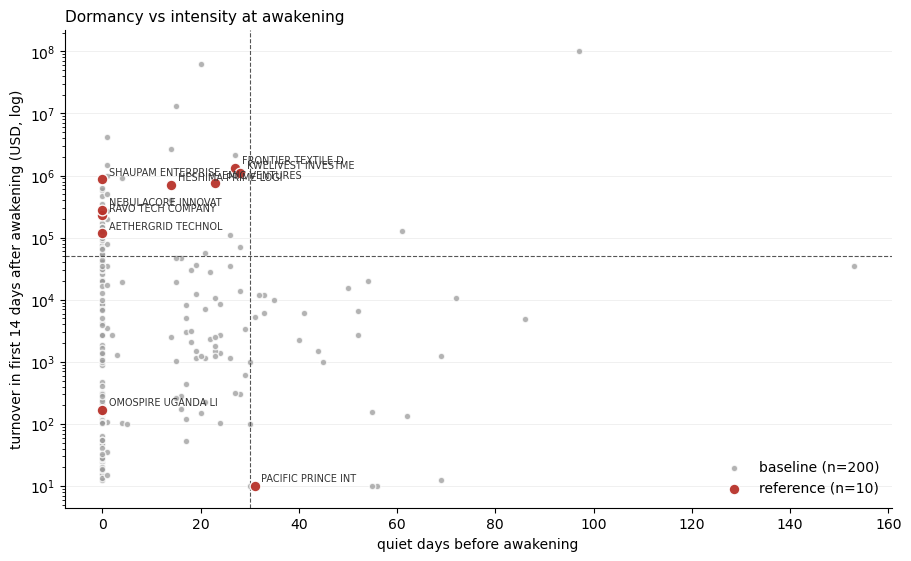

In [12]:
COL = {"cr": "#2a7f9e", "dr": "#c4682b", "chg": "#7a3b8f", "bal": "#3a3a3a", "quiet": "#e6e1d6",
       "ref": "#b8322a", "base": "#9a9a9a"}

fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
yfloor = 10
for g, c, sz, lab in [("baseline", COL["base"], 22, f"baseline (n={len(base)})"),
                      ("reference", COL["ref"], 60, f"reference (n={len(ref)})")]:
    s = summary[summary.group == g]
    ax.scatter(s.quiet_before_awake, s.wake_turnover.clip(lower=yfloor), s=sz, c=c, alpha=.75 if g == "baseline" else .95,
               edgecolors="white", linewidths=1, label=lab, zorder=3 if g == "reference" else 2)
for _, r in ref.iterrows():
    if pd.notna(r.quiet_before_awake):
        ax.annotate(str(r.ACCT_NAME)[:18], (r.quiet_before_awake, max(r.wake_turnover, yfloor)),
                    xytext=(5, 3), textcoords="offset points", fontsize=7, color="#333")
ax.axvline(QUIET_MIN_DAYS, color="#555", lw=.8, ls="--")
ax.axhline(WAKE_MIN_USD, color="#555", lw=.8, ls="--")
ax.set_yscale("log")
ax.set_xlabel("quiet days before awakening")
ax.set_ylabel(f"turnover in first {WAKE_DAYS} days after awakening (USD, log)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#eee", lw=.6)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Dormancy vs intensity at awakening", loc="left", fontsize=11)
fig.savefig(OUT / "dormancy_vs_wake_intensity.png", dpi=130)
plt.show()

## 9. Timelines — small multiples (same day-since-opening axis)

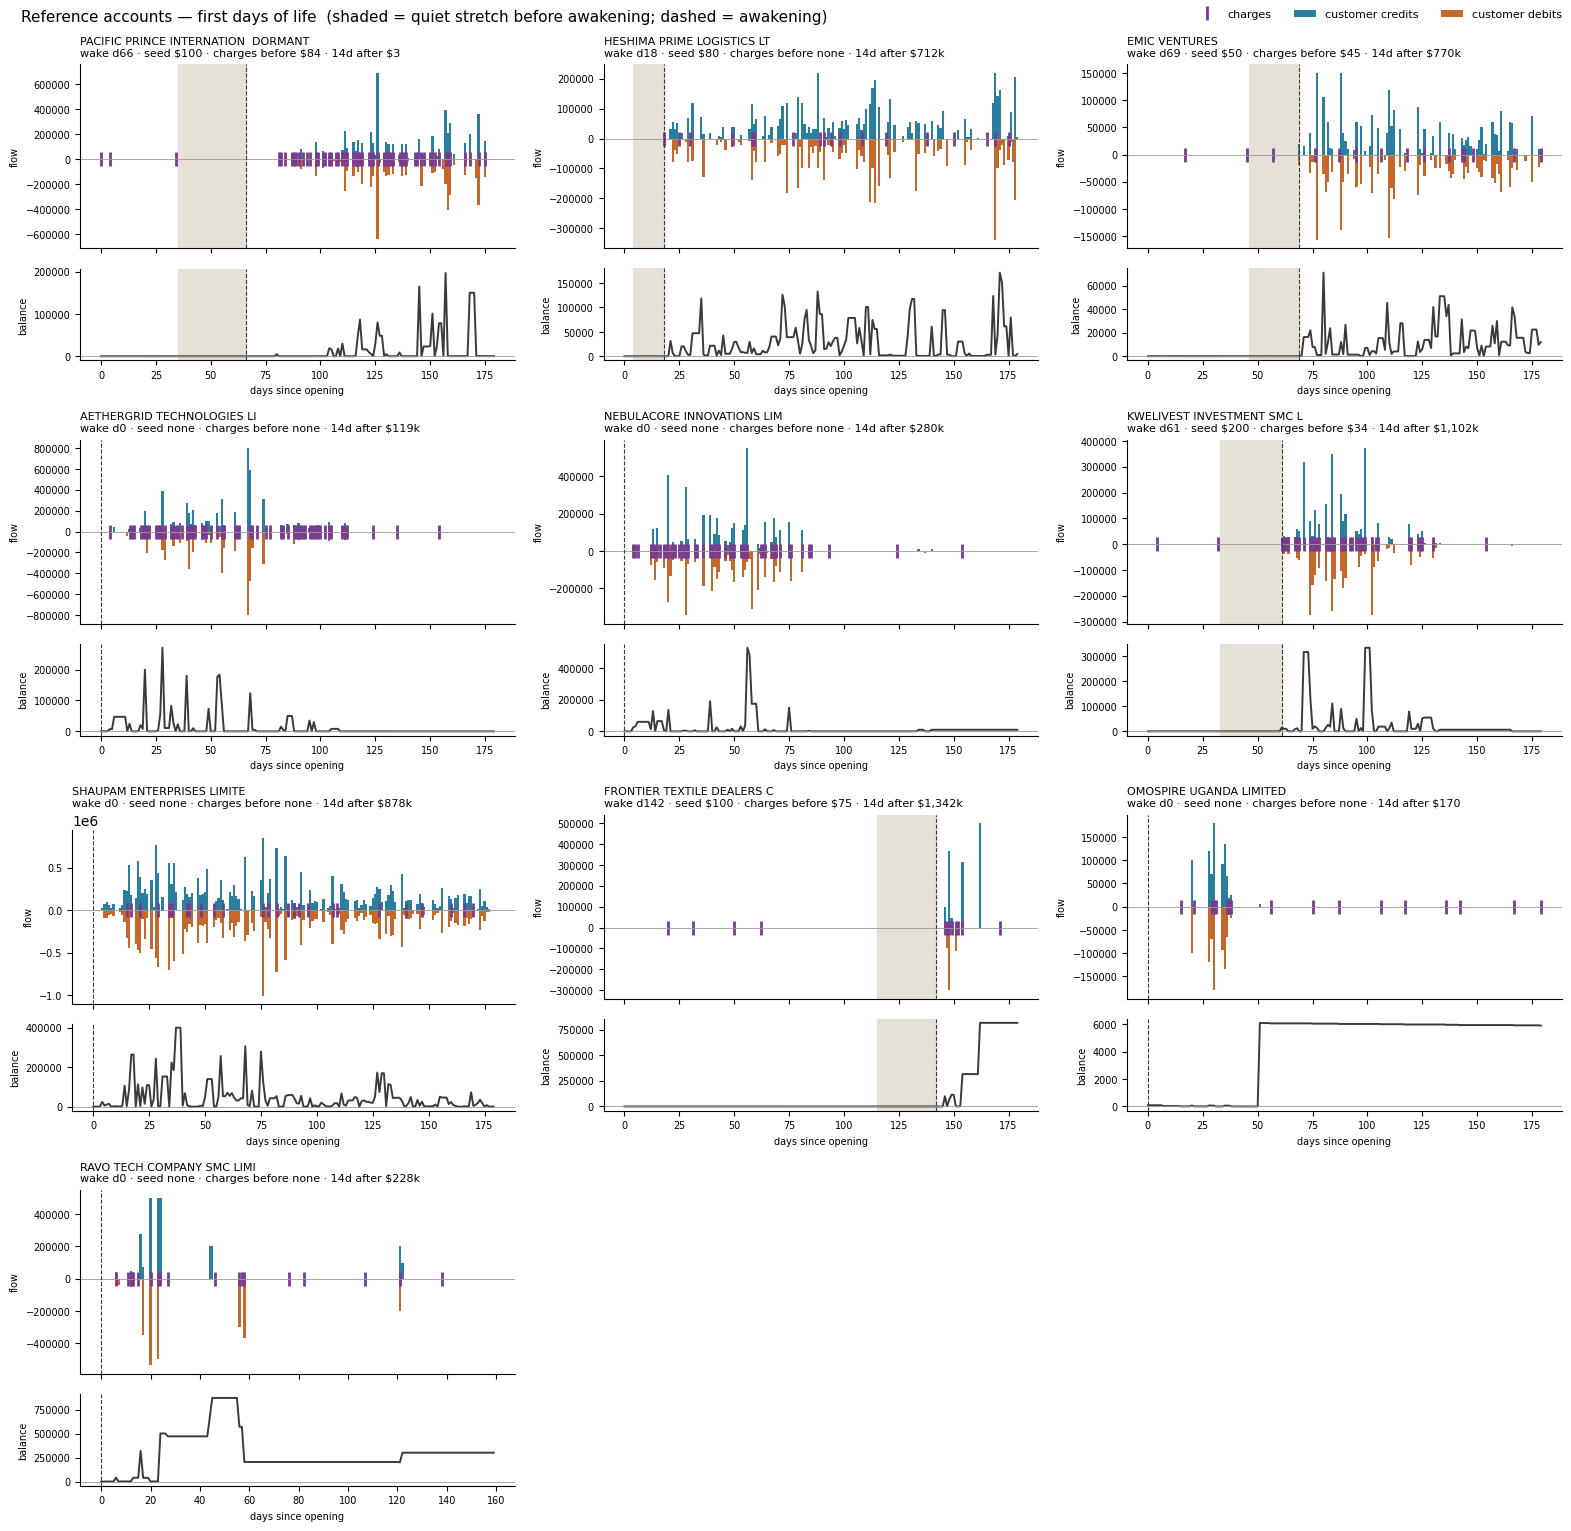

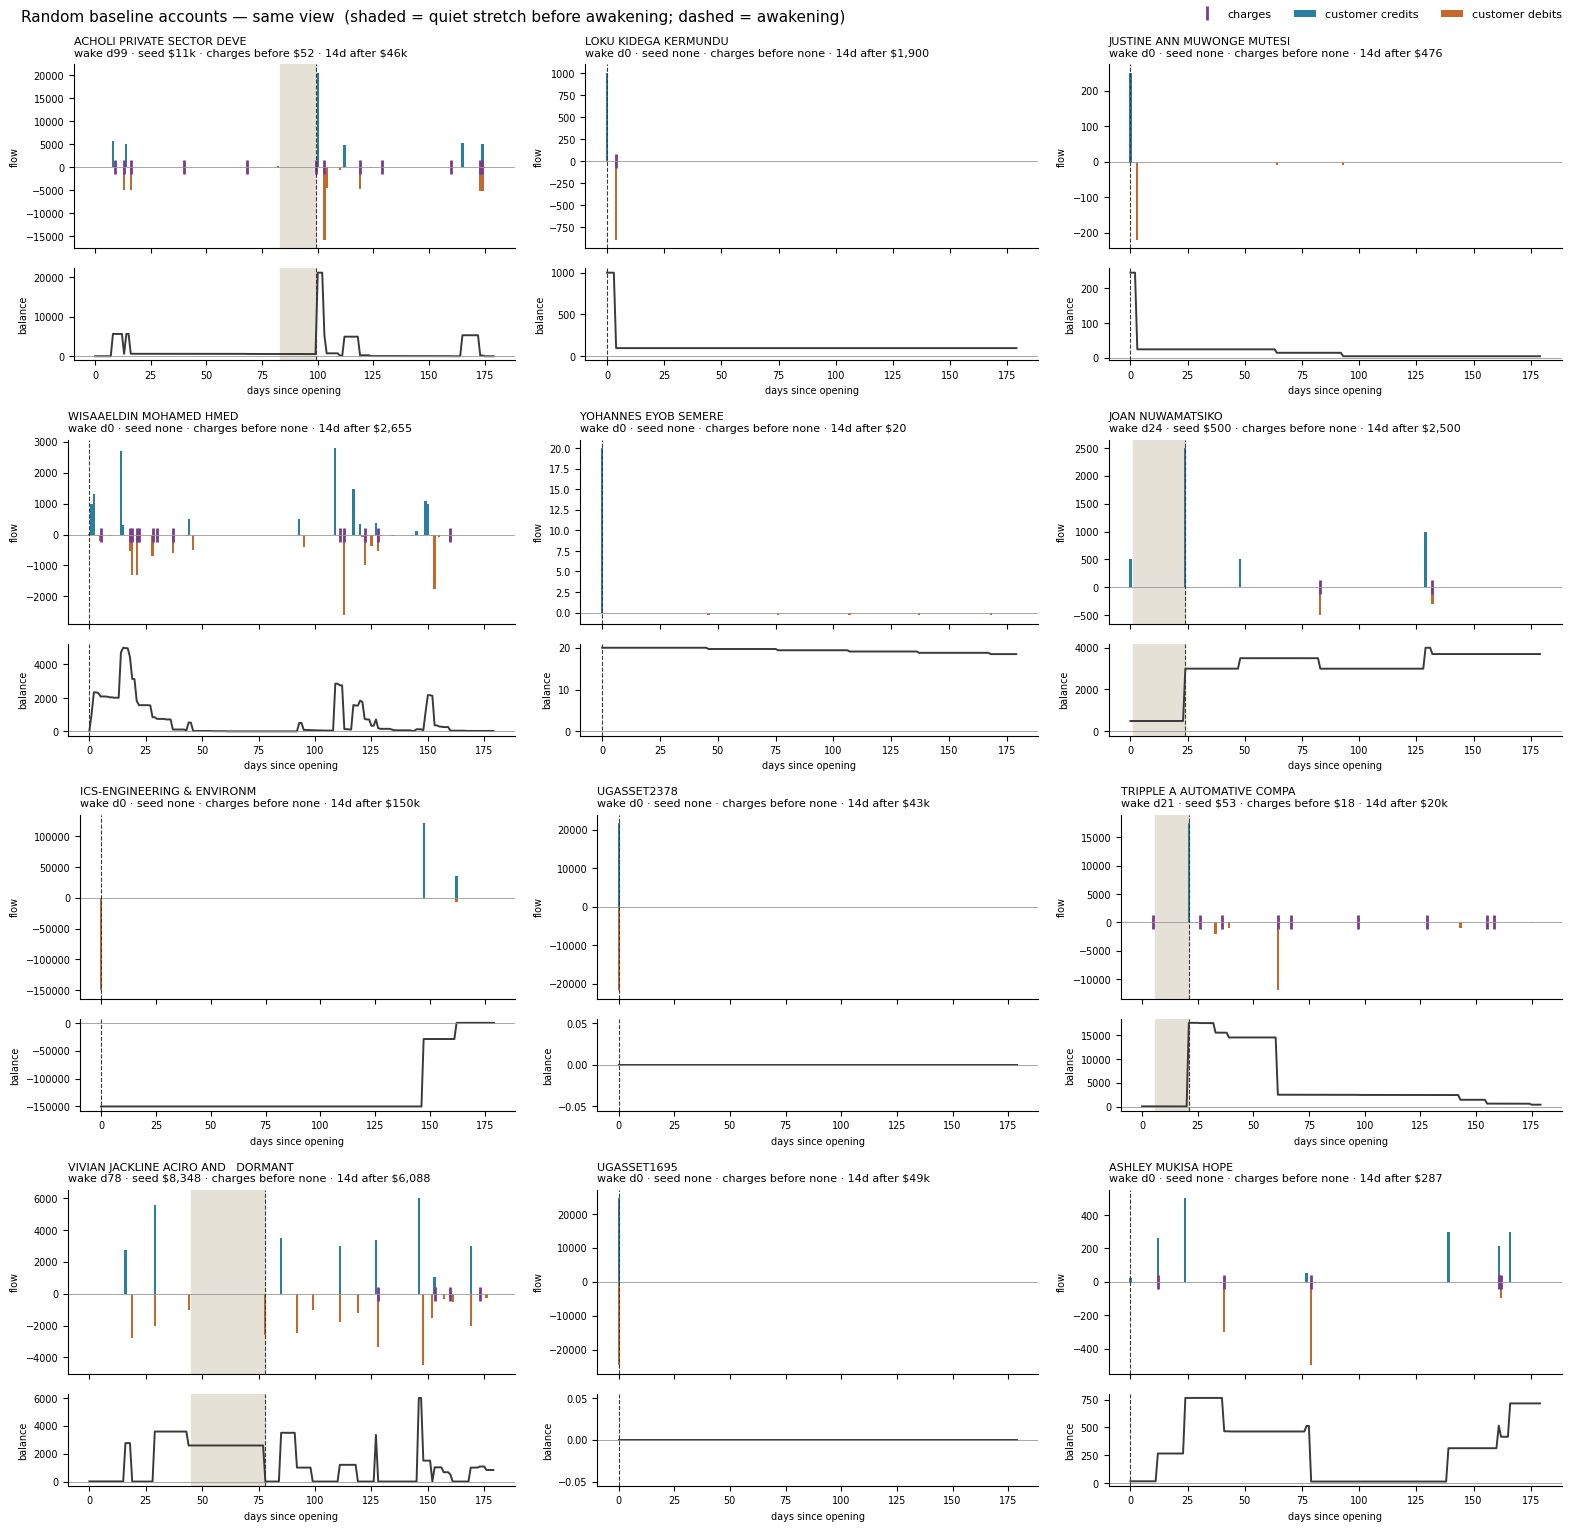

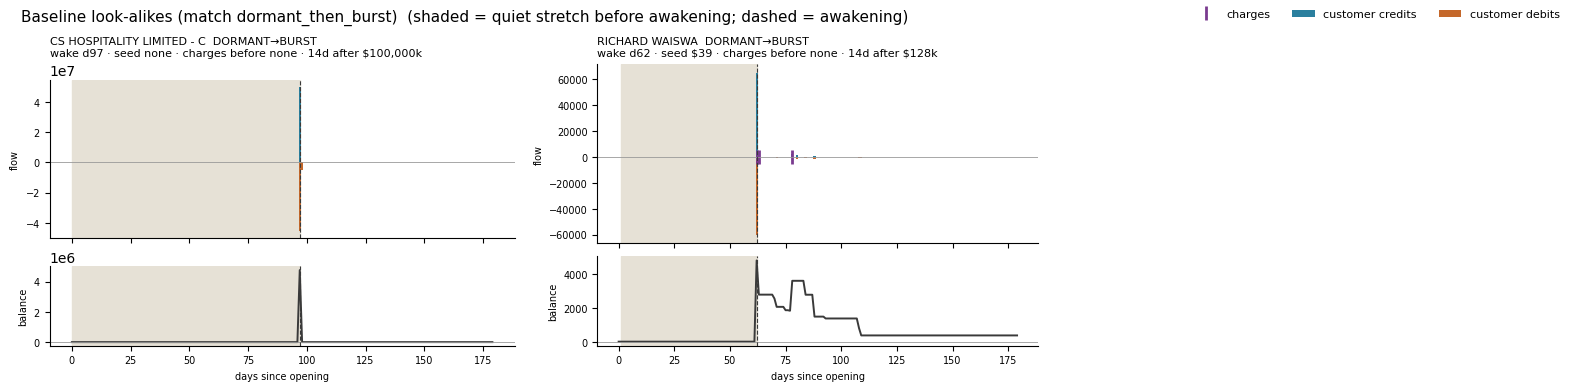

In [13]:
def fmt_usd(v):
    # "\$" stops matplotlib treating text between two dollar signs as math
    return "none" if not v or pd.isna(v) else (f"\\${v/1e3:,.0f}k" if v >= 1e4 else f"\\${v:,.0f}")

def plot_panels(acids, title, fname, ncols=3):
    acids = list(acids)
    if not acids:
        print(f"Nothing to plot for {title}"); return
    nrows = int(np.ceil(len(acids) / ncols))
    fig = plt.figure(figsize=(5.2 * ncols, 3.8 * nrows), constrained_layout=True)
    subs = np.atleast_1d(fig.subfigures(nrows, ncols)).ravel()
    s_idx = summary.set_index("ACID")
    for sf, acid in zip(subs, acids):
        d, s = timelines[acid], s_idx.loc[acid]
        ax, axb = sf.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [2, 1]})
        ax.bar(d.index, d.customer_cr, color=COL["cr"], width=1.0, label="customer credits")
        ax.bar(d.index, -d.customer_dr, color=COL["dr"], width=1.0, label="customer debits")
        chg = d.index[d.charge_dr > 0]
        ax.plot(chg, np.zeros(len(chg)), "|", color=COL["chg"], ms=10, mew=2, label="charges")
        ax.axhline(0, color="#999", lw=.6)
        axb.plot(d.index, d.balance, color=COL["bal"], lw=1.4)
        axb.axhline(0, color="#999", lw=.6)
        if pd.notna(s.awakening_day):
            a, qd = int(s.awakening_day), int(s.quiet_before_awake)
            for x in (ax, axb):
                if qd > 0:
                    x.axvspan(a - qd, a, color=COL["quiet"], zorder=0)
                x.axvline(a, color=COL["bal"], lw=.8, ls="--")
        tag = "DORMANT→BURST" if s.dormant_then_burst else ("DORMANT" if s.dormant_start else "")
        info = ""
        if pd.notna(s.awakening_day):
            info = (f"\nwake d{int(s.awakening_day)} · seed {fmt_usd(s.seed_amt)} · "
                    f"charges before {fmt_usd(s.charges_before_wake)} · {WAKE_DAYS}d after {fmt_usd(s.wake_turnover)}")
        ax.set_title(f"{str(s.ACCT_NAME)[:26]}  {tag}{info}", fontsize=8, loc="left")
        ax.tick_params(labelsize=7); axb.tick_params(labelsize=7)
        ax.set_ylabel("flow", fontsize=7); axb.set_ylabel("balance", fontsize=7)
        axb.set_xlabel("days since opening", fontsize=7)
        for x in (ax, axb):
            x.spines[["top", "right"]].set_visible(False)
    for sf in subs[len(acids):]:
        sf.set_visible(False)
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper right", ncols=3, fontsize=8, frameon=False)
    fig.suptitle(title + "  (shaded = quiet stretch before awakening; dashed = awakening)", fontsize=11, x=0.01, ha="left")
    fig.savefig(OUT / fname, dpi=130)
    plt.show()

plot_panels(ref.sort_values("ACCT_OPN_DATE").ACID, "Reference accounts — first days of life", "reference_timelines.png")
plot_panels(base.sample(n=min(12, len(base)), random_state=RANDOM_SEED).ACID,
            "Random baseline accounts — same view", "baseline_timelines.png")
plot_panels(lookalikes.ACID.head(12), "Baseline look-alikes (match dormant_then_burst)", "baseline_lookalikes.png")

## 10. Focus account

In [14]:
focus = summary[summary.ACCT_NAME.str.upper().str.contains(FOCUS_NAME, na=False)]
if focus.empty:
    print(f"No account name contains '{FOCUS_NAME}'")
else:
    for acid in focus.ACID:
        d = timelines[acid]
        print(summary.set_index("ACID").loc[acid, ["ACCT_NAME", "FORACID", "group"] + METRICS + FLAGS].to_string())
        active = d[(d.cust_n > 0) | (d.charge_dr > 0) | (d.gl_cr + d.gl_dr > 0)]
        display(active[["customer_cr", "customer_dr", "charge_dr", "gl_cr", "gl_dr", "balance"]].head(40).round(2))

ACCT_NAME                 FRONTIER TEXTILE DEALERS CO LIMITED
FORACID                                         9030027282317
group                                               reference
first_cr_day                                                0
first_dr_day                                              0.0
active_days                                                16
turnover_first30_share                               0.000062
charge_share_early                                   0.797462
longest_quiet                                              31
awakening_day                                             142
quiet_before_awake                                         27
seed_amt                                                100.0
charges_before_wake                                      75.4
wake_turnover                                      1342094.41
wake_match                                           0.618224
wake_active_days                                            8
dormant_

,customer_cr,customer_dr,charge_dr,gl_cr,gl_dr,balance
day,,,,,,
0,100.0,11.50,0.00,88.5,88.5,88.50
20,0.0,2.55,17.00,0.0,0.0,68.95
31,0.0,0.00,20.70,0.0,0.0,48.25
50,0.0,2.55,17.00,0.0,0.0,28.70
62,0.0,0.00,20.70,0.0,0.0,8.00
82,0.0,2.55,0.00,0.0,0.0,5.45
94,0.0,2.70,0.00,0.0,0.0,2.75
114,0.0,2.55,0.00,0.0,0.0,0.20
142,103.0,0.00,0.00,0.0,0.0,103.20


## 11. Export

In [16]:
summary["ACCT_NAME"] = [
    n if FOCUS_NAME in str(n).upper()
    else f"{'REF' if g == 'reference' else 'BASE'}{i:03d}"
    for i, (n, g) in enumerate(zip(summary.ACCT_NAME, summary.group))
]
summary = summary.drop(columns=["ACID", "FORACID", "CIF_ID"])

In [17]:
summary.to_csv(OUT / "early_metrics.csv", index=False)
comp.to_csv(OUT / "reference_vs_baseline.csv")
prevalence.to_csv(OUT / "flag_prevalence.csv")
lookalikes.to_csv(OUT / "baseline_lookalikes.csv", index=False)
pd.concat({a: d for a, d in timelines.items() if a in set(ref.ACID)}, names=["ACID"]).to_csv(OUT / "reference_daily_timelines.csv")
print("Saved to", OUT.resolve())

Saved to /home/A270827/experiments/AML/outputs/early_signals


## 12. Gate — what to decide from this

| What you see | Reading | Next step |
|---|---|---|
| `dormant_then_burst` clearly more common in reference than baseline, and better than `burst_on_wake` alone | Dormancy adds real early information | **Lead-time test:** for each reference account, the day it would first reach the current top 5% vs its awakening day |
| `burst_on_wake` separates as well as `dormant_then_burst` | The burst is the signal; dormancy is incidental | Build an awakening detector without the dormancy condition — simpler, covers immediate-start mules too |
| Neither separates (many baseline look-alikes) | Shape alone isn't enough | Combine with onboarding and shared-party signals |

Also check:
- `seed_amt` among dormant reference accounts: is there really a lump sum being eaten by charges, or are they empty until they wake?
- The look-alike table: where do those accounts rank in the current production screen?
- `wake_complete = False` rows: young accounts whose look-ahead is cut short, so their `wake_turnover` is understated.

With ~10 reference accounts, treat every number here as directional evidence, not a result.

In [ ]:
summary["ACCT_NAME"] = [
    n if FOCUS_NAME in str(n).upper()
    else f"{'REF' if g == 'reference' else 'BASE'}{i:03d}"
    for i, (n, g) in enumerate(zip(summary.ACCT_NAME, summary.group))
]
summary = summary.drop(columns=["FORACID", "CIF_ID"])